# Compare synthetic-control durations

A {term}`synthetic control` can be scored at more than one holdout length. This page keeps the treated unit, the {term}`donor pool`, and the decision rule fixed, then asks which requested origins can support every requested duration. Each eligible origin and duration is its own pre-origin fit. The duration comparison does not search the donor pool, and it does not pick a duration. A later section screens a constructed panel and does not recommend a launch.

The [fixed-target page](synthetic-control-design-pymc.ipynb) fits one horizon and translates that fit across a lift grid. Here the training window is the history before the origin, so a shorter holdout is not a prefix of a longer fit. Prefix reuse stays off: no equivalence test covers it.

:::{note}
Nothing on this page is a launch recommendation, a power curve, or a detection curve. Coverage of a translated interval is not a detection curve. The recommendation text says so on every result, including a clean historical description.
:::


## Setup

The panel is the first 48 rows of the built-in synthetic-control series. Sampling is short so the page stays executable. It is not a production posterior. {cite:t}`abadie2021using` is the method; {cite:t}`ferman2021imperfect` is why a zero-lift row that misses zero is a description of the fit, not a reason to launch.


In [1]:
import numpy as np
import pandas as pd

import causalpy as cp
from causalpy.design import DecisionRule, SyntheticControlPlanner
from causalpy.pymc_models import WeightedSumFitter

sample_kwargs = {
    "draws": 20,
    "tune": 20,
    "chains": 1,
    "cores": 1,
    "progressbar": False,
    "random_seed": 42,
}
decision = DecisionRule("positive", "cumulative", threshold=0.0, probability=0.95)
history = cp.load_data("sc").iloc[:48]
treated = "actual"
controls = ["a", "b", "c", "d", "e", "f", "g"]
planner = SyntheticControlPlanner(
    history,
    treated,
    controls,
    decision,
    random_seed=42,
    model=WeightedSumFitter(sample_kwargs=sample_kwargs),
)

## Preview before any fit

An origin is eligible only when every requested duration has a usable window there. Origin 44 can hold a 4-row window on this panel and cannot hold an 8-row window, so a request for both durations drops it before sampling. A request that has no eligible origin returns `insufficient-history` and does not fit.


In [2]:
preview = planner.preview_durations(
    (4, 8),
    (16, 44),
    absolute_lifts=(1.0,),
    target_lift=1.0,
)
print(preview.status)
print("eligible", preview.eligible_origins)
print(
    "ineligible",
    [(item.origin, item.reason) for item in preview.ineligible],
)
print("expected fits", preview.expected_counterfactual_fits, preview.expected_fits)
assert preview.status == "ready"
assert preview.eligible_origins == (16,)
assert preview.expected_counterfactual_fits == 2
assert planner.model.idata is None

short = planner.preview_durations(
    (8,),
    (44,),
    absolute_lifts=(1.0,),
    target_lift=1.0,
)
print(short.status)
assert short.status == "insufficient-history"
assert short.expected_fits == 0
assert planner.model.idata is None

ready
eligible (16,)
ineligible [(44, 'duration 8: horizon 8 extends 4 label(s) past the history.')]
expected fits 2 2
insufficient-history


## Compare common origins

Durations 4 and 8 are both feasible at origins 16 and 24. Origin 40 is reserved for the later audit and is not fitted here. Each of the four origin-duration pairs is one fit. Lifts are translated from that fit and the draws are dropped.


In [3]:
comparison = planner.compare_durations(
    (4, 8),
    (16, 24),
    absolute_lifts=(1.0,),
    target_lift=1.0,
    audit_origins=(40,),
)
print(comparison.status)
print(comparison.recommendation())
print("inference fits", comparison.n_inference_fits)
assert comparison.status == "historical-descriptive"
assert comparison.recommendation().startswith("No supported recommendation")
assert "No duration was selected." in comparison.recommendation()
assert comparison.n_inference_fits >= 4
assert planner.model.idata is None
assert comparison.sample_kwargs["draws"] == 20

Only 20 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (1 chains in 1 job)


NUTS: [beta, y_hat_sigma]


Sampling 1 chain for 20 tune and 20 draw iterations (20 + 20 draws total) took 0 seconds.


The number of samples is too small to check convergence reliably.


... (43 outputs left out)

Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


historical-descriptive
No supported recommendation. No duration was selected. Evidence level: historical-descriptive. This is a historical description, not a power curve and not a launch claim. Extrapolation beyond the evaluated durations is not a result.
inference fits 4


## Summary and plot

The summary has one row per duration. The recommendation column is `not-supported` on every row. The left panel is zero-lift cumulative bias. The right panel is the historical detection count at the requested lift. Neither panel is a power curve.


In [4]:
summary = comparison.summary()
assert summary["recommendation"].eq("not-supported").all()
assert summary["duration"].tolist() == [4, 8]
summary

,duration,target_lift,target_scale,evidence_level,calibration_evidence_level,persistent_bias,zero_lift_bias_cumulative,zero_lift_bias_average,zero_lift_mean_absolute_error,historical_detection_count,historical_detection_share,scored_count,failed_count,requested_count,not_run_count,n_inference_fits,cost,recovery_mean_error,truth_covers_share,recommendation
0,4,1.0,absolute,historical-descriptive,inconclusive,False,0.238990,0.059748,0.836035,2,1.0,2,0,2,0,2,None,0.238990,1.0,not-supported
1,8,1.0,absolute,historical-descriptive,inconclusive,False,0.037426,0.004678,2.447647,2,1.0,2,0,2,0,2,None,0.037426,1.0,not-supported


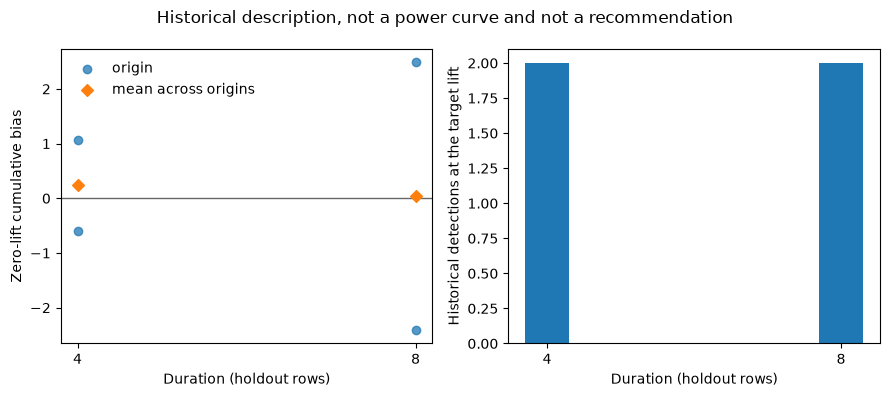

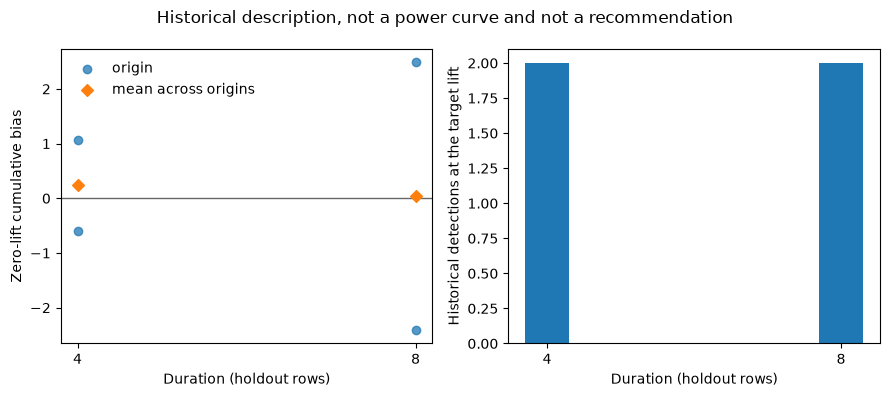

In [5]:
fig, _axes = comparison.plot()
fig

## Freeze, execute, and audit

`freeze(4)` records the caller's choice. It does not score the durations again, and it does not claim that 4 is better than 8. `execute` rebuilds the planned analysis from the stored units, estimator, priors, and sample settings. Training is every non-excluded row before the supplied treatment time. The post-period is the frozen holdout under the frozen cadence; later rows and cadence gaps are not fit. It is not a second search. `audit` fits only the reserved origin, at the frozen duration, and does not reselect. That origin has to sit strictly after every selection origin in the history index. An earlier audit is not untouched.


In [6]:
spec = comparison.freeze(4)
print(spec.selected_duration, spec.treated_unit, spec.control_units)
print(spec.sample_kwargs["draws"], spec.audit_origins)
print(spec.recommendation())
assert spec.selected_duration == 4
assert spec.sample_kwargs["draws"] == 20
assert spec.audit_origins == (40,)
assert spec.recommendation().startswith("No supported recommendation")

analysis = spec.execute(history, 16)
assert analysis.idata is not None

audit = spec.audit(history)
print(audit.status, audit.selected_duration, audit.n_inference_fits)
print(audit.recommendation())
assert audit.selected_duration == 4
assert audit.n_inference_fits >= 1
assert audit.recommendation().startswith("No supported recommendation")

Only 20 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.


4 actual ('a', 'b', 'c', 'd', 'e', 'f', 'g')
20 (40,)
No supported recommendation. The recorded duration is 4. Recording a duration is the caller's choice, not a recommendation. Evidence level: historical-descriptive. This is a historical description, not a power curve and not a launch claim. Extrapolation beyond the evaluated durations is not a result.


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (1 chains in 1 job)


NUTS: [beta, y_hat_sigma]


Sampling 1 chain for 20 tune and 20 draw iterations (20 + 20 draws total) took 0 seconds.


... (18 outputs left out)

Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


historical-descriptive 4 1
No supported recommendation. The recorded duration is 4. Recording a duration is the caller's choice, not a recommendation. Evidence level: historical-descriptive. This is a historical description, not a power curve and not a launch claim. Extrapolation beyond the evaluated durations is not a result.


## Persistent null bias

A treated series that sits far above every donor cannot be matched by a convex combination of the {term}`donor pool`. The zero-lift cumulative bias is then the same sign in every scored window, so `persistent_bias` is true. The comparison still returns. It does not correct the bias, and it still has no supported recommendation. The qualification engine has not landed.


In [7]:
biased_history = pd.DataFrame(
    {
        "a": 0.0,
        "b": 0.1,
        "c": -0.1,
        "treated": 8.0 + 0.05 * np.sin(np.arange(24)),
    }
)
bias_planner = SyntheticControlPlanner(
    biased_history,
    "treated",
    ["a", "b", "c"],
    decision,
    random_seed=42,
    model=WeightedSumFitter(sample_kwargs=sample_kwargs),
)
biased = bias_planner.compare_durations(
    (4, 6),
    (4, 8),
    absolute_lifts=(1.0,),
    target_lift=1.0,
)
print(biased.persistent_bias, biased.status)
print(biased.summary()[["duration", "zero_lift_bias_cumulative"]])
print(biased.recommendation())
assert biased.persistent_bias is True
assert biased.status == "historical-descriptive"
assert (
    "Persistent null bias is visible and is not corrected." in biased.recommendation()
)

/Users/benjamv/git/CausalPy-worktrees/issue-721/causalpy/experiments/synthetic_control.py:166: UserWarning: Control units ['a' (r=undefined, likely constant), 'b' (r=undefined, likely constant), 'c' (r=undefined, likely constant)] have pre-treatment correlation below 0.0 or undefined with treated unit 'treated'. Consider excluding them from the donor pool. Use cp.plot_correlations() to inspect. See Abadie (2021) for guidance on donor pool selection.
/Users/benjamv/git/CausalPy-worktrees/issue-721/causalpy/experiments/synthetic_control.py:167: UserWarning: Convex hull assumption may be violated: 4 pre-intervention time points (100.0% above, 0.0% below control range). The synthetic control method requires the treated unit to lie within the convex hull of control units. Consider: (1) adding more diverse control units, (2) using a model with an intercept (e.g., ITS with control predictors), or (3) using the Augmented Synthetic Control Method. See glossary term 'Convex hull condition' for m

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (1 chains in 1 job)


NUTS: [beta, y_hat_sigma]


Sampling 1 chain for 20 tune and 20 draw iterations (20 + 20 draws total) took 0 seconds.


The number of samples is too small to check convergence reliably.


... (43 outputs left out)

Sampling: [beta, y_hat, y_hat_sigma]


Sampling: [y_hat]


Sampling: [y_hat]


True historical-descriptive
   duration  zero_lift_bias_cumulative
0         4                   31.85583
1         6                   47.83438
No supported recommendation. No duration was selected. Evidence level: historical-descriptive. This is a historical description, not a power curve and not a launch claim. Persistent null bias is visible and is not corrected. The qualification engine has not landed. Extrapolation beyond the evaluated durations is not a result.


## A failed fit stays in the counts

A fitter that raises is a failed fit, not a missing row and not a quieter sampler. The failed count stays on the summary. The recommendation is still unsupported. Freezing a failed comparison is allowed when a duration was evaluated; freezing a comparison that never fitted is not.


In [8]:
class BrokenFitter(WeightedSumFitter):
    def sample_posterior(self, **kwargs):
        raise RuntimeError("sampling failed")


failed = SyntheticControlPlanner(
    history,
    treated,
    controls,
    decision,
    random_seed=42,
    model=BrokenFitter(sample_kwargs=sample_kwargs),
).compare_durations(
    (4,),
    (16,),
    absolute_lifts=(1.0,),
    target_lift=1.0,
)
print(failed.status, int(failed.summary()["failed_count"].sum()))
assert failed.status == "fit-failed"
assert int(failed.summary()["failed_count"].sum()) >= 1
assert failed.summary()["recommendation"].eq("not-supported").all()
assert failed.sample_kwargs["draws"] == 20

refused = planner.compare_durations(
    (4, 8),
    (16, 24),
    absolute_lifts=(1.0,),
    target_lift=1.0,
    max_fits=1,
)
assert refused.status == "budget-exhausted"
assert refused.n_inference_fits == 0
assert planner.model.idata is None
try:
    refused.freeze(4)
except ValueError as exc:
    print(exc)

fit-failed 1
Cannot freeze a duration from a budget-exhausted comparison. The duration was not evaluated, and freeze does not select a replacement.


## Fit and memory limits

The budget above stopped at one expected fit and did not sample. A draws setting whose translated arrays would exceed the per-window byte ceiling returns `memory-exhausted` from the preview, again without fitting. Passing a larger `max_fits` is the caller's choice. The comparison does not lower `draws` or `tune` to squeeze under either limit.


In [9]:
memory = planner.preview_durations(
    (8,),
    (16,),
    absolute_lifts=(1.0,),
    target_lift=1.0,
    sample_kwargs={"draws": 200_000, "chains": 1},
)
print(memory.status, memory.estimated_window_bytes, memory.max_window_bytes)
assert memory.status == "memory-exhausted"
assert memory.estimated_window_bytes > memory.max_window_bytes
assert planner.model.idata is None

memory-exhausted 51200000 33554432


## One measured resource envelope

The cells above use 20 draws so the page can be re-executed. A separate local run of `profile_durations` used the same 48-row panel, durations 4 and 8, and origins 16 and 24, with `draws=200`, `tune=200`, `chains=2`, `cores=1`, and `random_seed=42`. This page does not repeat that run.

| quantity | cold | warm |
| --- | ---: | ---: |
| wall seconds | 7.24 | 4.82 |
| fit seconds | 5.32 | 4.27 |
| score seconds | 0.020 | 0.019 |

The warm run recorded 6 inference fits: four window fits and two learned-null fits. Peak resident set size was 574,537,728 bytes. That figure is the process high-water mark on macOS 27.2.1 arm64, including the PyTensor cache, under Python 3.12.9, NumPy 2.5.4, PyMC 6.3.2, PyTensor 3.3.4, and CausalPy 1.0.0rc1. It is not a per-call allocation and not a reason to launch.

That run also reported an r-hat above 1.01 and an effective sample size per chain below 100. Two chains at 200 draws are a resource envelope, not a converged study. Fitting and scoring were measured separately. The score step was about 0.02 seconds against more than 4 seconds of fitting.


## Screen a constructed panel

The duration comparison above keeps the donor pool fixed. Screening asks a different question: among eligible units, which single-target designs look tight on a weighted-proportion holdout, and which touch outcomes an operator might actually care about.

`precise` is a convex combination of `d0` and `d1` plus a small shift, so its screening proxy is tight and its supplied relevance is low. `relevant` is a noisy copy of `d0`, so the proxy is worse, the supplied cost is lower, and the supplied relevance is higher. `d0` and `d1` are eligible too. They are not a hidden donor pool outside the search.

The proxy is weighted-proportion holdout RMSE on rows before the selection origin. Lower is tighter in sample. It is not a veto, not the analysis, and not a reason to launch. The Pareto table uses historical detection share, supplied cost, and supplied relevance. A tight proxy can still be dominated on those axes. No winner is selected.


In [1]:
import resource
import time

screen_seed = sum(map(ord, "issue 319 constructed screen"))
screen_rng = np.random.default_rng(screen_seed)
screen_index = pd.Index(range(36), name="t")
donor_0 = screen_rng.normal(size=36)
donor_1 = 0.8 * donor_0 + screen_rng.normal(scale=0.3, size=36)
precise = 0.55 * donor_0 + 0.45 * donor_1 + 0.05
relevant = 0.2 * donor_0 + screen_rng.normal(scale=1.1, size=36)
screen = pd.DataFrame(
    {"precise": precise, "relevant": relevant, "d0": donor_0, "d1": donor_1},
    index=screen_index,
)
screen_kwargs = {
    "draws": 8,
    "tune": 8,
    "chains": 1,
    "cores": 1,
    "progressbar": False,
}
screen_planner = SyntheticControlPlanner(
    screen,
    "precise",
    ["d0", "d1"],
    decision,
    model=WeightedSumFitter(sample_kwargs=screen_kwargs),
    random_seed=screen_seed,
)
started = time.perf_counter()
screened = screen_planner.search(
    durations=(6,),
    selection_origins=(12,),
    eligible_units=("precise", "relevant", "d0", "d1"),
    costs={"precise": 100.0, "relevant": 5.0, "d0": 80.0, "d1": 80.0},
    representativeness={
        "precise": 0.1,
        "relevant": 0.9,
        "d0": 0.05,
        "d1": 0.05,
    },
    target_lift=1.0,
    absolute_lifts=(1.0,),
    sample_kwargs=screen_kwargs,
    max_fits=8,
)
screen_seconds = time.perf_counter() - started
screen_rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
screen_table = screened.summary.set_index("treated_unit")
assert (
    screen_table.loc["precise", "proxy_score"]
    < screen_table.loc["relevant", "proxy_score"]
)
assert screened.global_optimum is False
assert screened.recommendation().startswith("No supported recommendation")
assert "No winner was selected." in screened.recommendation()
assert screened.n_inference_fits == 4
print(f"wall_seconds {screen_seconds:.2f}")
print(f"peak_rss_bytes {screen_rss}")
print(screened.recommendation())
screened.summary[["treated_unit", "proxy_score", "cost", "relevance", "status"]]

wall_seconds 9.93
peak_rss_bytes 656523264
No supported recommendation. The Pareto set is the evaluated non-dominated set across historical detection share, supplied cost, and supplied relevance. It is not a global optimum, not an inferred CPIC or spend response, and not a launch recommendation. Screen scores are weighted-proportion holdout RMSE proxies, not the analysis. Evaluated comparisons are historical descriptions. No winner was selected.


,treated_unit,proxy_score,cost,relevance,status
0,precise,0.044717,100.0,0.10,evaluated
1,relevant,0.892961,5.0,0.90,evaluated
2,d0,0.216620,80.0,0.05,evaluated
3,d1,0.228072,80.0,0.05,evaluated


In [2]:
screened.pareto_table

,candidate_id,treated_unit,duration,sensitivity,cost,relevance,dominated
0,"[""precise"",[""d0"",""d1"",""relevant""]]",precise,6,1.0,100.0,0.10,True
1,"[""relevant"",[""d0"",""d1"",""precise""]]",relevant,6,1.0,5.0,0.90,False
2,"[""d0"",[""d1"",""precise"",""relevant""]]",d0,6,1.0,80.0,0.05,True
3,"[""d1"",[""d0"",""precise"",""relevant""]]",d1,6,1.0,80.0,0.05,True


## What the screen did not decide

On this run `precise` had the lower holdout RMSE, about 0.045 against about 0.893 for `relevant`, and was still dominated. `relevant` stayed in the Pareto set because its supplied cost was lower and its supplied relevance was higher, while historical detection share tied at 1. The tight proxy was not the operationally useful geo. No winner was selected.

The cell recorded 9.93 wall seconds and a process high-water mark of 656,523,264 bytes. That figure includes the PyTensor cache. It was measured on macOS arm64 under Python 3.12.9, NumPy 2.5.4, PyMC 6.3.2, PyTensor 3.3.4, and CausalPy 1.0.0rc1, with 8 draws, 8 tuning steps, one chain, and four inference fits. It is not a per-call allocation and not a reason to launch.

## References

:::{bibliography}
:filter: docname in docnames
:::
